In [1]:
import pygplates
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('/Users/Simon/GIT/GPlatesClassStruggle/')
from reconstruction_classes import *

import plate_driver as pdriver

%load_ext autoreload
%autoreload 2

M2016 = ReconstructionModel('Matthews++2016')
M2016.add_rotation_model('/Users/simon/GIT/agegrid-dev/input_files/Rotations/Matthews_etal_GPC_2016_410-0Ma_GK07.rot')
M2016.add_static_polygons('/Users/simon/GIT/agegrid-dev/input_files/StaticPolygons/Muller_etal_AREPS_2016_StaticPolygons.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_MesozoicCenozoic_PlateTopologies.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_Paleozoic_PlateTopologies.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_TopologyBuildingBlocks.gpml')


In [2]:
delta_time = 10.
forces = ['slab_pull','slab_suction']
slab_suction_to_slab_pull_ratio = 0.25
    
results = []    

for reconstruction_time in np.arange(10,400,10):
    
    snapshot = M2016.plate_snapshot(reconstruction_time)

    result = pdriver.get_torques_for_plate_snapshot(snapshot, reconstruction_time, delta_time,
                                                    forces, slab_suction_to_slab_pull_ratio)
    
    results.append((reconstruction_time,result))
    
    

Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting s

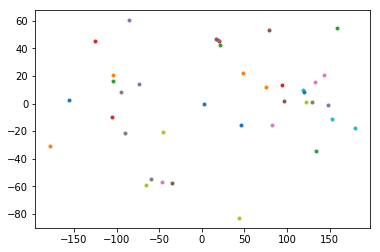

In [3]:
for result in results:
    
    plt.figure()
    for point in zip(*result[1])[1]:
        plt.plot(point.to_lat_lon()[1], point.to_lat_lon()[0], '.')
        
    plt.show()
    break
    


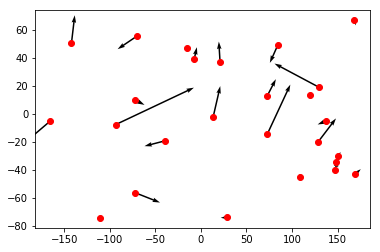

In [4]:
for result in results[5:6]:
    
    plt.figure()
    for point,vel in zip(zip(*result[1])[1],zip(*result[1])[4]):
        if vel is not None:
            plt.plot(point.to_lat_lon()[1], point.to_lat_lon()[0], 'ro')
            plt.quiver(point.to_lat_lon()[1],
                       point.to_lat_lon()[0],
                       vel.get_y(),
                       vel.get_x(),
                       color='k', units='xy', scale=0.02, width=1.5)
    break

In [5]:
target_plate_id = 301
reconstruction_time = 10

snapshot = M2016.plate_snapshot(reconstruction_time)

forces = ['slab_pull']
result = pdriver.get_torque_for_plate_polygon(snapshot, target_plate_id, reconstruction_time, delta_time,
                                              forces, slab_suction_to_slab_pull_ratio)
    
print pygplates.PointOnSphere(result[2].to_normalised().to_xyz()).to_lat_lon()

forces = ['slab_suction']
result = pdriver.get_torque_for_plate_polygon(snapshot, target_plate_id, reconstruction_time, delta_time,
                                              forces, slab_suction_to_slab_pull_ratio)
    
print pygplates.PointOnSphere(result[2].to_normalised().to_xyz()).to_lat_lon()


(57.10020788731055, 123.35880402521143)
(1.935133611632355, 165.7418678193773)


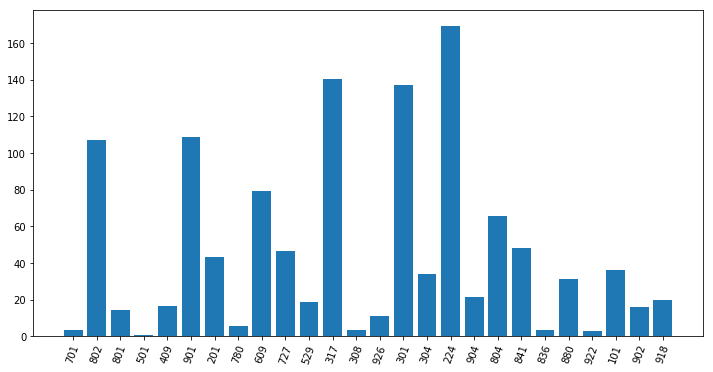

In [6]:
reconstruction_time = 60.
forces = ['slab_pull','slab_suction']

snapshot = M2016.plate_snapshot(reconstruction_time)

result = pdriver.get_torques_for_plate_snapshot(snapshot, reconstruction_time, delta_time,
                                                forces, slab_suction_to_slab_pull_ratio)

plate_ids = []
angles = []

for res in result:
    if res[4] is not None:
        angle = pygplates.Vector3D.angle_between(res[4],res[6])
        plate_ids.append(res[0])
        angles.append(np.degrees(angle))
    
    
width = 0.8
fig, ax = plt.subplots(figsize=(12,6))
plt.bar(np.arange(len(angles)),angles)
ax.set_xticks(np.arange(len(angles)))
ax.set_xticklabels(plate_ids,rotation=70)
plt.show()
        

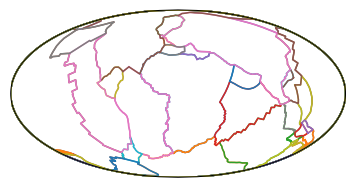

In [7]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

ax = plt.axes(projection=ccrs.Mollweide())

for polygon in snapshot.resolved_topologies:
    
    ax.plot(polygon.get_resolved_geometry().to_lat_lon_array()[:,1],
            polygon.get_resolved_geometry().to_lat_lon_array()[:,0],
            transform=ccrs.Geodetic())
    
plt.show()
  

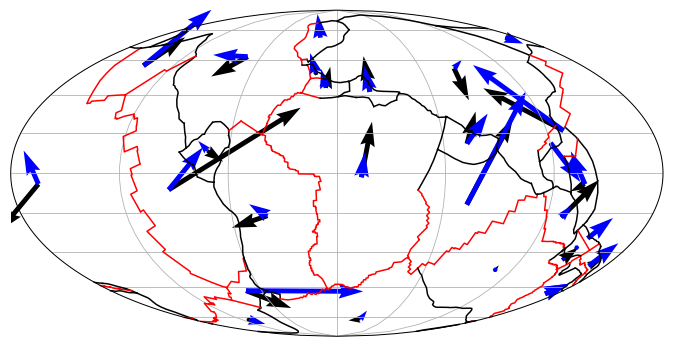

In [15]:
plt.figure(figsize=(12,6))
ax = plt.axes(projection=ccrs.Mollweide())

for boundary in snapshot.resolved_topological_sections:
    shared_sub_segments = boundary.get_shared_sub_segments()
    for shared_sub_segment in shared_sub_segments:
        if shared_sub_segment.get_resolved_feature().get_feature_type() == pygplates.FeatureType.gpml_subduction_zone:
            boundary_color = 'black'
        elif shared_sub_segment.get_resolved_feature().get_feature_type() == pygplates.FeatureType.gpml_mid_ocean_ridge:
            boundary_color = 'red'
        else:
            boundary_color = 'black'
        ax.plot(shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,1],
                shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,0],
                transform=ccrs.Geodetic(), color=boundary_color)

x = []; y = []; u = []; v = []
for point,vel in zip(zip(*results[5][1])[1],zip(*results[5][1])[4]):
    if vel is not None:
        x.append(point.to_lat_lon()[1])
        y.append(point.to_lat_lon()[0])
        u.append(vel.get_y())
        v.append(vel.get_x())
ax.quiver(np.array(x),
          np.array(y),
          np.array(u),
          np.array(v),
          transform=ccrs.PlateCarree())

x = []; y = []; u = []; v = []
for point,vel in zip(zip(*results[5][1])[1],zip(*results[5][1])[6]):
    if vel is not None:
        x.append(point.to_lat_lon()[1])
        y.append(point.to_lat_lon()[0])
        u.append(vel.get_y())
        v.append(vel.get_x())
ax.quiver(np.array(x),
          np.array(y),
          np.array(u),
          np.array(v),
          transform=ccrs.PlateCarree(), color='blue')

ax.set_global()
ax.gridlines()
plt.show()
